# 多系统融合权重：冻结历史比较

## tl;dr
近 3/5 日直接加权未证明改善概率；5 日中心 RMSE 降约 0.40%，线性池 CRPS 却升约 0.34%。生产保持。分层 CRPS 是下一研究方向，尚未通过晋级。

## Context & Methods
33 个非 ASOS 站；08-28 至 09-19，604 条中心评分，515 条恢复分布评分。所有候选逐时点只读已知标签。

### Key Assumptions
历史 TAF 可用性筛选；不是全 45 站；CRPS 是市场桶代表点的线性池评分，不是最终服务。外层曾被研究查看，分层 CRPS 为后加探索臂。详见 PROTOCOL.md / REPORT.md。

In [1]:
import json, sys, hashlib
from pathlib import Path
base=Path.cwd()
sys.path.insert(0,str(base))
from compare import study, summarize
guard=study.Guard()
r=json.loads((base/'results.json').read_text())
rows=json.loads((base/'scores.json').read_text())
v=json.loads((base/'validation.json').read_text())
for name,sha in r['inputs_sha256'].items():
    assert hashlib.sha256((study.ROOT/name).read_bytes()).hexdigest()==sha
assert len(rows)==r['n']==604
print('33 stations / 604 center cases / 515 distribution cases / 23 days')

33 stations / 604 center cases / 515 distribution cases / 23 days


## Data
输入为原服务中心、历史成员与参数 hash；无包和 provisional 样本不伪造。

In [2]:
a=json.loads((base/'reconstruction_audit.json').read_text())
print(a['counts'])
print('Independent CRPS checks:', v['independent_crps_cases'])
print('Max integration discrepancy:', v['independent_crps_max_error'])

{'packet_missing': 450, 'provisional_scope_not_reconstructed': 69, 'reconstructed': 516}
Independent CRPS checks: 6695
Max integration discrepancy: 1.7763568394002505e-15


## Results
负 CRPS 差表示比原权重线性池好。区间为连续 3 日 moving-block bootstrap 95% 描述区间；多候选、短历史，不能视为晋级检验。

In [3]:
labels={'current': 'Current', 'equal': 'Equal', 'station3': 'Station 3d', 'station5': 'Station 5d', 'station5_shrink': 'Station 5d + shrink', 'station_lead_eb21': 'Station / lead MSE', 'center_stack21': 'Center stacking', 'crps_hier21': 'Hierarchical CRPS*'}
b=r['arms']['current']
print(f"{'Arm':26} {'RMSE C':>9} {'Pool CRPS':>10} {'NLL':>9}")
for arm,label in labels.items():
    s=summarize(rows,arm)
    assert s['rmse']==r['arms'][arm]['rmse']
    print(f"{label:26} {s['rmse']:9.4f} {s['pool_crps']:10.6f} {s['pool_nll']:9.6f}")

Arm                           RMSE C  Pool CRPS       NLL
Current                       1.2886   0.662243  1.584997
Equal                         1.2865   0.666433  1.592135
Station 3d                    1.2901   0.666671  1.579776
Station 5d                    1.2834   0.664508  1.581833
Station 5d + shrink           1.2859   0.661650  1.583430
Station / lead MSE            1.2909   0.665156  1.586477
Center stacking               1.2828   0.660667  1.584723
Hierarchical CRPS*            1.2892   0.661270  1.579986


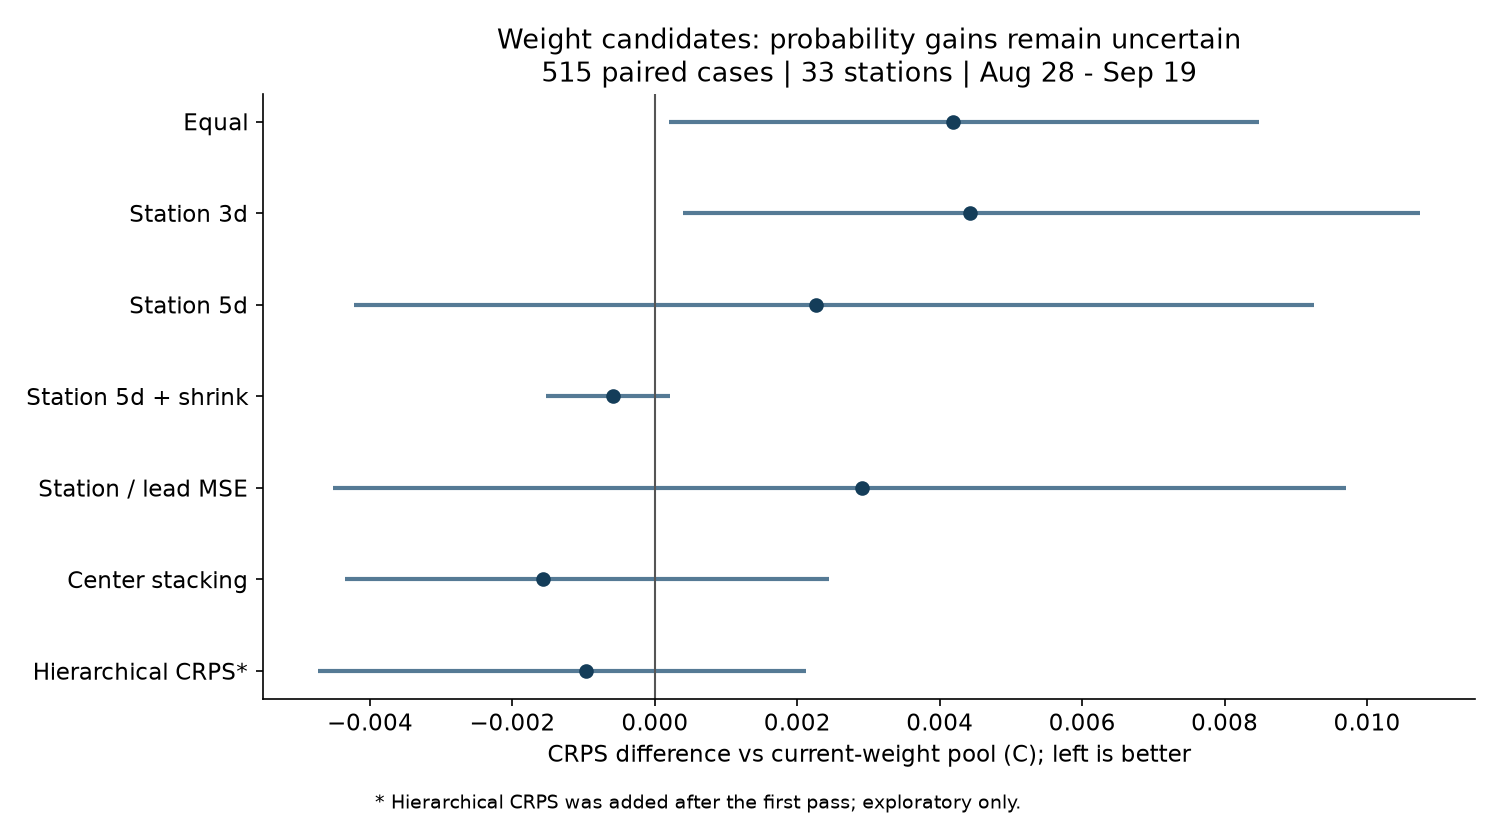

In [4]:
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display, Image
plt.rcParams.update({'font.size':11,'axes.spines.top':False,'axes.spines.right':False})
arms=[a for a in labels if a!='current']; y=np.arange(len(arms))
d=np.array([r['arms'][a]['pool_crps']-b['pool_crps'] for a in arms])
ci=np.array([r['arms'][a]['pool_crps_delta_ci'] for a in arms])
fig,ax=plt.subplots(figsize=(10,5.5))
ax.hlines(y,ci[:,0],ci[:,1],color='#557A95',linewidth=2)
ax.scatter(d,y,color='#143D59',zorder=3)
ax.axvline(0,color='#555555',linewidth=1)
ax.set_yticks(y,[labels[a] for a in arms]);ax.invert_yaxis()
ax.set_xlabel('CRPS difference vs current-weight pool (C); left is better')
ax.set_title('Weight candidates: probability gains remain uncertain\n515 paired cases | 33 stations | Aug 28 - Sep 19')
fig.text(.25,.02,'* Hierarchical CRPS was added after the first pass; exploratory only.',fontsize=9)
fig.tight_layout(rect=(0,.04,1,1));fig.savefig(base/'crps_comparison.png',dpi=150);plt.close(fig)
display(Image(filename=str(base/'crps_comparison.png')))

小幅改善候选的区间均跨零。近 3/5 日直接加权并未给出稳定概率优势。

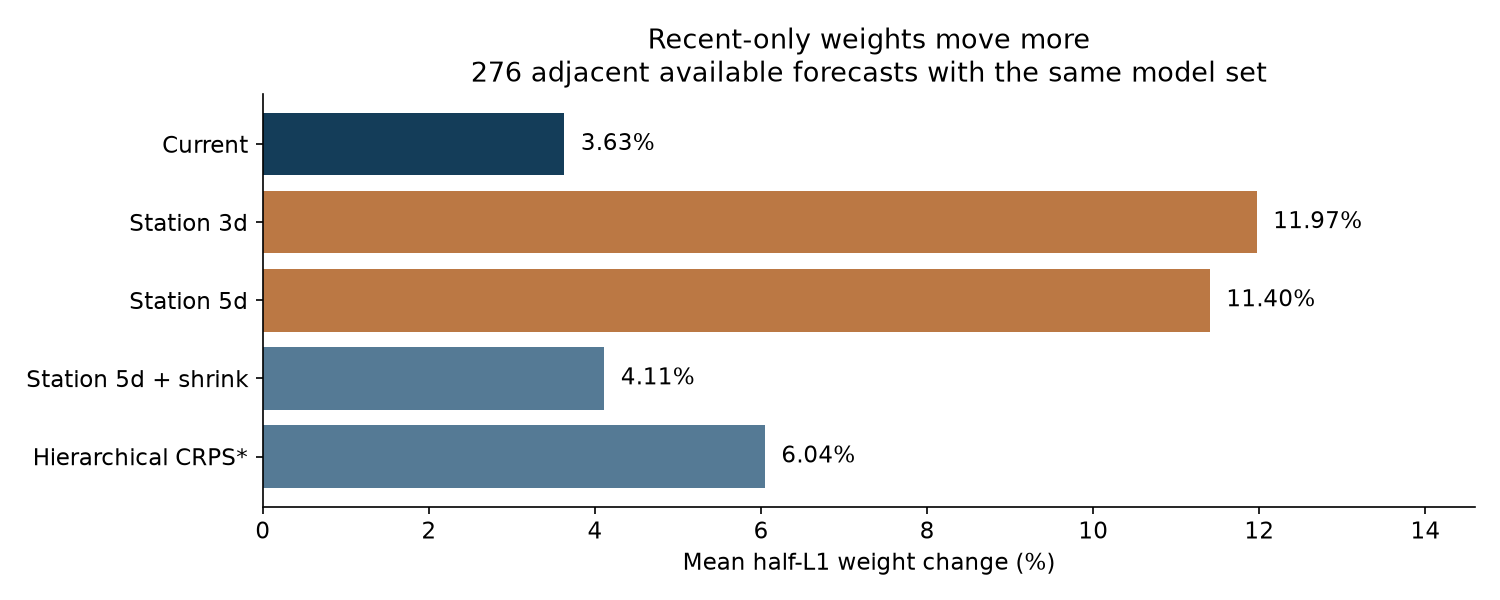

In [5]:
arms=['current','station3','station5','station5_shrink','crps_hier21']
values=[100*v['same_set_turnover'][a]['mean'] for a in arms]
fig,ax=plt.subplots(figsize=(10,4))
ax.barh([labels[a] for a in arms],values,color=['#143D59','#BB7844','#BB7844','#557A95','#557A95'])
ax.invert_yaxis();ax.set_xlim(0,max(values)*1.22)
for i,value in enumerate(values):ax.text(value+.2,i,f'{value:.2f}%',va='center')
ax.set_xlabel('Mean half-L1 weight change (%)')
ax.set_title('Recent-only weights move more\n276 adjacent available forecasts with the same model set')
fig.tight_layout();fig.savefig(base/'weight_turnover.png',dpi=150);plt.close(fig)
display(Image(filename=str(base/'weight_turnover.png')))

## Takeaways
保留现行权重；统一成绩账本、全队/提前量先验、站点收缩、短窗弱修正、最终服务 proper-score 验收。下一主线是补齐历史服务链复现与 45 站 canonical 标签；不通过新天气分档追本窗噪声。

Sources：samples.json（上轮冻结）、enrichment.json、reconstructed.json、scores.json、results.json、validation.json。来源 hash 在 manifest.json；重跑计算用 compare.py，独立校验用 validate.py。